# Module 6 — Difference-in-Differences

Part of the Causal Inference Playbook. Course program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The running question: did NSW (National Supported Work), a US job-training program for men with very low earnings, raise the earnings of the men who took it?
- The men who took the program are called the treated men. They're compared with men drawn from the PSID (Panel Study of Income Dynamics), a US household survey, who didn't take it: the comparison men. Each man has "before" columns: facts about him from before the program, such as his age, his education and his earlier earnings. The outcome is his earnings after the program.
- Modules 3–5 compared the two groups' earnings after the program, once the groups were made alike on the "before" columns. That works only if every trait that affects both who took the program and earnings has a column.
- Module 6 uses difference-in-differences (DiD). A group's change = (the group's mean earnings after the program) − (the group's mean earnings before the program). The DiD estimate = (the treated men's change) − (the comparison men's change).
- What can go wrong: the treated men's change without the program is never seen, so DiD uses the comparison men's change in its place. The treated men applied while out of work, so their earnings may have been about to rise anyway, by more than the comparison men's. DiD would then count that extra rise as the program's effect.

**What this module produces:**
1. A DiD estimate of the program's effect on the real data. Then two checks of DiD's key assumption: that without the program, both groups' earnings would have changed alike. One check uses only earnings from before the program, which an analyst usually has. The other check uses the applicants a lottery kept out of the program, the same men Modules 1–5 used for the known answer. These men show how the treated men's earnings would have changed without the program. Most real studies have no such men, so an analyst usually can't run this second check.
2. DiD combined with weighting: DiD on comparison men given weights, so that as a group they look like the treated men before the program (the method of Module 5, recapped in worked example 2).
3. DiD when a change starts in different years in different places, on a US state law about self-defence (the castle-doctrine law).

## From the curriculum

> ## <u>Module 6 — Difference-in-Differences</u>
>
> **Overlap with the A/B Testing Playbook:** the basic DiD idea is recapped
> in this module, with a pointer to the Playbook's Module 8.
> The basic two-group, two-period comparison on
> made-up numbers with a known effect is in
> [A/B Testing Playbook, Module 8, Part 2](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/08_quasi_experiments.ipynb).
> This module adds real data, a check of the key assumption against a known
> answer, DiD combined with weighting, and changes that start in different
> years.
>
> **Concepts**
> - DiD (difference-in-differences): compare how much each group's mean
>   outcome changed from before to after, not the outcome itself.
>   DiD ATT (average treatment effect on the treated: the program's effect on
>   the men who took it) = (treated men's mean change) − (comparison men's
>   mean change).
> - What DiD removes: a gap between the two groups' earnings that is the same
>   size before the program and after the program. The gap is still there in
>   each period, but DiD measures only how much the gap changed. The analyst
>   doesn't need to know why the gap is there.
> - Parallel trends: without the program, the treated men's mean earnings
>   would have changed by the same number of dollars as the comparison men's.
> - The before-program check: did the two groups' earnings change alike
>   between two years before the program? Passing it doesn't prove
>   parallel trends.
> - DiD with weighting: DiD on comparison men given weights (Module 5), so that
>   as a group they look like the treated men before the program.
> - Changes that start in different years (staggered adoption): one DiD per
>   start-year group against the groups that never changed, the event study
>   (the per-group DiD, computed year by year), and the one-regression shortcut (a
>   single regression with one column per state and one per year, the usual
>   tool).
>
> **Why it matters**
> DiD is the usual tool when a change reaches some groups and not others,
> and there is data from before and after the change. DiD removes a gap
> between the groups that is the same size before and after, and the analyst
> doesn't need to know why the gap is there. DiD rests on parallel trends,
> which usually can't be checked directly after the change. So the analyst
> has to know when parallel trends is likely to fail.
>
> **Worked example**
> 1. NSW (National Supported Work) job-training data vs the PSID (Panel Study
>    of Income Dynamics) men: DiD from 1975 to 1978, the before-program check,
>    and a check of parallel trends against the applicants a lottery kept out
>    of the program.
> 2. DiD with weighting on the same data, next to DiD and weighting alone.
> 3. Castle-doctrine laws (laws that remove the duty to retreat before using
>    deadly force in self-defence outside the home), passed by 21 US states in
>    different years (2005–2009): one DiD per group, an event study, and the one-regression
>    shortcut.
>
> **Resources**
> - [Causal Inference: The Mixtape, ch. 9 "Difference-in-Differences"](https://mixtape.scunning.com/09-difference_in_differences)
>   (Scott Cunningham, ~60 min for sections 9.2–9.5, verified): the basic
>   DiD calculation, parallel trends, event studies, and the
>   same castle-doctrine data.
> - [The Effect, ch. 18 "Difference-in-Differences"](https://theeffectbook.net/ch-DifferenceinDifference.html)
>   (Nick Huntington-Klein, ~60 min, verified): parallel trends, rollout
>   designs with several start years (18.2.6, 18.3.1) and picking the
>   comparison group by matching: pairing each treated unit with the most
>   similar untreated one, as in Module 4 (18.3.2).
>
> **Exercise type:** redo DiD, the before-program check, the lottery check and
> DiD with weighting with the CPS (Current Population Survey, a monthly US labour
> survey) comparison group. Fully worked.
>
> **Interview angle:** "We launched feature X in the markets where spend had
> dipped. Spend there rose 8% the next month, against 3% in the other
> markets. Is X worth 5 points?"

## Lesson

### The data

- The treated men: 185 men who took NSW in 1976 or 1977. They had applied, and a lottery let them in.
- The comparison men: 2,490 men drawn from the PSID, who didn't apply to the program, so didn't take it.
- The earnings columns: 1974 and 1975 earnings (before the program) and 1978 earnings (after the program). All earnings are in US dollars per year. Worked example 1 uses only these three columns. Worked example 2 adds the other "before" columns: age, education, race, marriage and degree.
- The benchmark: the same lottery kept 260 applicants out: the lottery men. The lottery, not the men, decided who got in, so the 185 treated men and the 260 lottery men differ only by chance. So the lottery men's mean 1978 earnings shows what the treated men would have earned without the program. The treated men's mean minus the lottery men's mean is the program's effect on the treated men, with no selection bias (the part of a gap that comes from the groups being different to begin with).
- The naive gap: the plain comparison of the treated men's mean 1978 earnings with the PSID men's. It mixes the program's effect with how different the two groups were.

**The motive:** the benchmark is the answer each method below should get close to. The naive gap is the unadjusted comparison each method tries to improve on.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

import common
from common import show

# load_lalonde loads the NSW data, named after the economist LaLonde, who first used it to test non-experimental methods against the experiment
exp = common.load_lalonde("experimental")  # the lottery: 185 treated men (treat = 1) and the 260 lottery men (treat = 0)
psid = common.load_lalonde("psid")  # the same 185 treated men, plus the 2,490 PSID men (treat = 0)
nsw_t = exp[exp.treat == 1].copy()
lottery = exp[exp.treat == 0].copy()
psid_c = psid[psid.treat == 0].copy()
COLS8 = ["age", "education", "black", "hispanic", "married", "nodegree", "re74", "re75"]

r1 = lambda v: round(float(v), 1)  # every printed result is computed from the printed (rounded) numbers, so each line checks by hand
benchmark = r1(nsw_t.re78.mean()) - r1(lottery.re78.mean())
print("Benchmark")
print(f"    = (mean 1978 earnings, treated men, {len(nsw_t)} men) - (mean 1978 earnings, lottery men, {len(lottery)} men)")
print(f"    = {nsw_t.re78.mean():,.1f} - {lottery.re78.mean():,.1f} = {benchmark:,.1f}")
print()
naive = r1(nsw_t.re78.mean()) - r1(psid_c.re78.mean())
print("Naive gap")
print(f"    = (mean 1978 earnings, treated men, {len(nsw_t)} men) - (mean 1978 earnings, PSID men, {len(psid_c):,} men)")
print(f"    = {nsw_t.re78.mean():,.1f} - {psid_c.re78.mean():,.1f} = {naive:,.1f}")

Benchmark
    = (mean 1978 earnings, treated men, 185 men) - (mean 1978 earnings, lottery men, 260 men)
    = 6,349.1 - 4,554.8 = 1,794.3

Naive gap
    = (mean 1978 earnings, treated men, 185 men) - (mean 1978 earnings, PSID men, 2,490 men)
    = 6,349.1 - 21,553.9 = -15,204.8


**Observation:** the naive gap, (−$15,204.8), makes the program look harmful. The benchmark, $1,794.3, says it raised earnings.

### Difference-in-differences

The basic DiD idea was first taught in [A/B Testing Playbook, Module 8, Part 2](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/08_quasi_experiments.ipynb). This module doesn't rely on it: everything needed is taught here.

Modules 3–5 compared the treated men's 1978 earnings with the comparison men's. DiD compares how much each group's earnings changed:
- A man's change = (his 1978 earnings) − (his 1975 earnings). 1975 is the last year before the program, and 1978 is after it.
- DiD ATT = (the treated men's mean change) − (the PSID men's mean change). The treated men's change includes the program, and the DiD ATT asks what the program added. ATT is the average treatment effect on the treated: how much the program changed the treated men's 1978 earnings, on average.

How DiD differs from the naive gap:
- The naive gap compares 1978 earnings, so the naive gap contains the whole gap between the two groups.
- DiD also removes the gap that was already there in 1975: DiD ATT = (naive gap) − (gap in 1975).
- Gap in 1975 = (treated men's mean 1975 earnings) − (PSID men's mean 1975 earnings).
- If the gap between the two groups is the same size in 1975 and 1978, the subtraction removes the gap, and only the program's effect is left.

What DiD assumes: parallel trends. Without the program, the treated men's mean earnings would have changed from 1975 to 1978 by the same number of dollars as the PSID men's mean earnings did. The name comes from a chart of each group's mean earnings by year, shown in step 1: the treated men's line without the program would run parallel to the PSID men's line. If parallel trends holds, the PSID men's mean change stands in for the treated men's mean change without the program, and the DiD ATT is the program's effect.

The treated men's change without the program is never seen, so parallel trends can't be checked on the treated men themselves. Worked example 1 checks parallel trends in two ways: step 2 with the check an analyst can usually run, and step 3 with the lottery men, who stand in for the treated men without the program. Most real studies have no such men.

## Worked example 1: DiD on the real data

### Step 1 of 3: the DiD estimate

What does DiD give for the program's effect, and how sure is the DiD ATT estimate?

**The motive:** the naive gap, (−$15,204.8), compares 1978 earnings alone. If the PSID men already earned far more than the treated men in 1975, and the gap is about the same number of dollars in 1978, DiD removes the gap, and the estimate should move toward the benchmark.

The table below shows each group's mean 1975 and 1978 earnings. The same men are in both years, so a group's mean change equals (the group's mean 1978 earnings) − (the group's mean 1975 earnings), and the table computes it from the two means.

The 95% confidence interval shows how much the DiD ATT estimate could move if the study were rerun on another sample of treated men and PSID men:
- Standard error: how far the DiD ATT estimate would typically move from one rerun to the next.
- Spread of the change = the standard deviation of the change, one number for each group =<br>
  = square root of ((sum over the group's men of (the man's change − the group's mean change)²) ÷ (the group's number of men − 1)).<br>
  The more the men's changes differ from one another, the larger the spread.
- The DiD ATT is a difference of two means: the mean change of 185 treated men minus the mean change of 2,490 PSID men, two separate groups. So the DiD ATT's standard error comes from the usual formula for a difference of two means of separate groups: standard error = square root of ((spread of the change, treated men)² ÷ 185 + (spread of the change, PSID men)² ÷ 2,490).
- 95% confidence interval = (DiD ATT estimate) ± (1.96 × standard error).

group          men  mean 1975 earnings  mean 1978 earnings  mean change = 1978 - 1975
treated men    185             1,532.1             6,349.1                    4,817.0
PSID men     2,490            19,063.3            21,553.9                    2,490.6



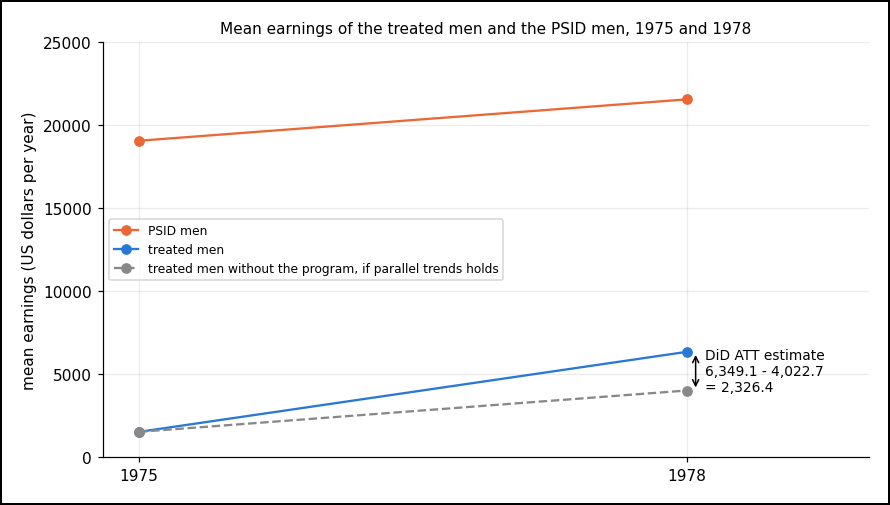

DiD ATT estimate
    = (treated men's mean change) - (PSID men's mean change)
    = 4,817.0 - 2,490.6 = 2,326.4

Gap in 1975 = 1,532.1 - 19,063.3 = -17,531.2
DiD ATT = (naive gap) - (gap in 1975) = (-15,204.8) - (-17,531.2) = 2,326.4

Spread of the change, treated men (185 men)
    = square root of ((sum of (man's change - group's mean change)²) ÷ (185 - 1))
    = square root of (12,600,761,844.2 ÷ 184) = 8,275.4

Spread of the change, PSID men (2,490 men)
    = square root of ((sum of (man's change - group's mean change)²) ÷ (2,490 - 1))
    = square root of (292,290,386,326.2 ÷ 2,489) = 10,836.6

Standard error
    = square root of ((spread of the change, treated men)² ÷ 185 + (spread of the change, PSID men)² ÷ 2,490)
    = square root of (8,275.4² ÷ 185 + 10,836.6² ÷ 2,490) = 646.0

95% confidence interval
    = (DiD ATT estimate) ± (1.96 × standard error)
    = 2,326.4 ± (1.96 × 646.0) = 2,326.4 ± 1,266.2 = 1,060.2 to 3,592.6


In [2]:
for g in (nsw_t, lottery, psid_c):
    g["change"] = g.re78 - g.re75  # each man's change from 1975 to 1978
    g["earlier_change"] = g.re75 - g.re74  # each man's change from 1974 to 1975, before the program

def mean_change(g, before, after):
    # The group's mean change, from the printed (rounded) means, so it checks by hand.
    return r1(r1(g[after].mean()) - r1(g[before].mean()))

def means_table(groups, before, after, years):
    show(pd.DataFrame([(name, f"{len(g):,}", f"{g[before].mean():,.1f}", f"{g[after].mean():,.1f}", f"{mean_change(g, before, after):,.1f}")
                       for name, g in groups],
                      columns=["group", "men", f"mean {years[0]} earnings", f"mean {years[1]} earnings", f"mean change = {years[1]} - {years[0]}"]))

def interval(t, c, column, estimate, name, cname, label, tname="treated men"):
    # Standard error of a difference of two means, from the printed (rounded) spreads, and the 95% interval.
    spreads = []
    for g, group in [(t, tname), (c, cname)]:
        x = g[column].astype(float)  # double precision, so the sum and the spread are exact to the printed decimals
        total, n = ((x - x.mean()) ** 2).sum(), len(g)
        spreads.append(r1(np.sqrt(total / (n - 1))))
        print(f"Spread of the {name}, {group} ({n:,} men)")
        print(f"    = square root of ((sum of (man's {name} - group's mean {name})²) ÷ ({n:,} - 1))")
        print(f"    = square root of ({total:,.1f} ÷ {n - 1:,}) = {spreads[-1]:,.1f}")
        print()
    s_t, s_c = spreads
    se = r1(np.sqrt(s_t**2 / len(t) + s_c**2 / len(c)))
    margin = r1(1.96 * se)
    print("Standard error")
    print(f"    = square root of ((spread of the {name}, {tname})² ÷ {len(t)} + (spread of the {name}, {cname})² ÷ {len(c):,})")
    print(f"    = square root of ({s_t:,.1f}² ÷ {len(t)} + {s_c:,.1f}² ÷ {len(c):,}) = {se:,.1f}")
    print()
    print("95% confidence interval")
    print(f"    = ({label}) ± (1.96 × standard error)")
    print(f"    = {estimate:,.1f} ± (1.96 × {se:,.1f}) = {estimate:,.1f} ± {margin:,.1f} = {r1(estimate - margin):,.1f} to {r1(estimate + margin):,.1f}")
    return r1(estimate - margin), r1(estimate + margin)

means_table([("treated men", nsw_t), ("PSID men", psid_c)], "re75", "re78", (1975, 1978))
print()
t75, t78, c75, c78 = (r1(g[col].mean()) for g, col in [(nsw_t, "re75"), (nsw_t, "re78"), (psid_c, "re75"), (psid_c, "re78")])
without = r1(t75 + r1(c78 - c75))  # the treated men's 1978 mean without the program, if parallel trends holds
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot([1975, 1978], [c75, c78], "o-", color=common.ORANGE, label="PSID men")
ax.plot([1975, 1978], [t75, t78], "o-", color=common.BLUE, label="treated men")
ax.plot([1975, 1978], [t75, without], "o--", color=common.GREY, label="treated men without the program, if parallel trends holds")
ax.annotate("", xy=(1978.05, t78), xytext=(1978.05, without), arrowprops=dict(arrowstyle="<->", color="black"))
ax.text(1978.1, (t78 + without) / 2, f"DiD ATT estimate\n{t78:,.1f} - {without:,.1f}\n= {r1(t78 - without):,.1f}", va="center", fontsize=9)
ax.set_xticks([1975, 1978])
ax.set_xlim(1974.8, 1979)
ax.set_ylim(0, 25000)
ax.set_ylabel("mean earnings (US dollars per year)")
ax.set_title("Mean earnings of the treated men and the PSID men, 1975 and 1978", fontsize=10)
ax.legend(loc="center left", fontsize=8)
plt.tight_layout()
plt.show()
ch_t, ch_c = mean_change(nsw_t, "re75", "re78"), mean_change(psid_c, "re75", "re78")
att_did = r1(ch_t - ch_c)
print("DiD ATT estimate")
print("    = (treated men's mean change) - (PSID men's mean change)")
print(f"    = {ch_t:,.1f} - {ch_c:,.1f} = {att_did:,.1f}")
print()
gap75_psid = r1(r1(nsw_t.re75.mean()) - r1(psid_c.re75.mean()))
print(f"Gap in 1975 = {nsw_t.re75.mean():,.1f} - {psid_c.re75.mean():,.1f} = {gap75_psid:,.1f}")
print(f"DiD ATT = (naive gap) - (gap in 1975) = ({naive:,.1f}) - ({gap75_psid:,.1f}) = {r1(naive - gap75_psid):,.1f}")
print()
did_interval = interval(nsw_t, psid_c, "change", att_did, "change", "PSID men", "DiD ATT estimate")

**Observation:**
- In 1975, before the program, the PSID men's mean earnings were $19,063.3, and the treated men's $1,532.1.
- DiD moves the estimate from the naive gap, (−$15,204.8), to $2,326.4. Distance above the benchmark = (DiD ATT estimate) − (benchmark) = 2,326.4 − 1,794.3 = $532.1.
- The 95% confidence interval runs from $1,060.2 to $3,592.6. The interval doesn't contain 0, and the interval contains the benchmark, $1,794.3.

**Conclusion:** removing the difference between the groups that stays the same from 1975 to 1978 takes the estimate from (−$15,204.8) to $2,326.4, much closer to the benchmark. The benchmark is inside the DiD interval, so chance could explain some or all of the $532.1. The distance above the benchmark, $532.1, may also have another source: the PSID men's change may be a poor stand-in for the treated men's change without the program. Steps 2 and 3 check that.

### Step 2 of 3: the before-program check

Did the two groups' earnings change alike before the program?

**The motive:** parallel trends is about 1975 to 1978. Checking parallel trends directly needs the treated men's 1978 earnings without the program, which are never seen. What an analyst can usually check is the years before the program. If the two groups' earnings changed by different amounts before the program, parallel trends after it is in doubt. If they changed alike, that doesn't prove parallel trends after 1975, but there's no warning.

- A man's earlier change = (his 1975 earnings) − (his 1974 earnings). Both years are before the program.
- Difference in earlier change = (treated men's mean earlier change) − (PSID men's mean earlier change). It's 0 if the two groups' earnings changed alike from 1974 to 1975.
- The rule, the usual one: the check passes if the 95% confidence interval of the difference contains 0. Passing means no difference too big to be chance was found, not that there is none. The standard error is the same formula as in step 1, on the earlier change.

In [3]:
means_table([("treated men", nsw_t), ("PSID men", psid_c)], "re74", "re75", (1974, 1975))
print()
e_t, e_c = mean_change(nsw_t, "re74", "re75"), mean_change(psid_c, "re74", "re75")
pre_gap = r1(e_t - e_c)
print("Difference in earlier change")
print("    = (treated men's mean earlier change) - (PSID men's mean earlier change)")
print(f"    = ({e_t:,.1f}) - ({e_c:,.1f}) = {pre_gap:,.1f}")
print()
low, high = interval(nsw_t, psid_c, "earlier_change", pre_gap, "earlier change", "PSID men", "difference in earlier change")
print()
print(f"Passes (the interval contains 0)? {'yes' if low < 0 < high else 'no'}")
print()
rows = []
for name, g in [("treated men", nsw_t), ("PSID men", psid_c)]:
    zero = g.re74 == 0
    for label, part in [("$0", zero), ("above $0", ~zero)]:
        rows.append((name, label, f"{part.sum():,}", f"{part.mean():.1%}", f"{g.earlier_change[part].mean():,.1f}"))
show(pd.DataFrame(rows, columns=["group", "1974 earnings", "men", "share of the group", "mean change = 1975 - 1974"]))

group          men  mean 1974 earnings  mean 1975 earnings  mean change = 1975 - 1974
treated men    185             2,095.6             1,532.1                     -563.5
PSID men     2,490            19,428.7            19,063.3                     -365.4

Difference in earlier change
    = (treated men's mean earlier change) - (PSID men's mean earlier change)
    = (-563.5) - (-365.4) = -198.1

Spread of the earlier change, treated men (185 men)
    = square root of ((sum of (man's earlier change - group's mean earlier change)²) ÷ (185 - 1))
    = square root of (2,634,668,696.7 ÷ 184) = 3,784.0

Spread of the earlier change, PSID men (2,490 men)
    = square root of ((sum of (man's earlier change - group's mean earlier change)²) ÷ (2,490 - 1))
    = square root of (144,222,452,519.5 ÷ 2,489) = 7,612.1

Standard error
    = square root of ((spread of the earlier change, treated men)² ÷ 185 + (spread of the earlier change, PSID men)² ÷ 2,490)
    = square root of (3,784.0² ÷ 185 + 7,

**Observation:** from 1974 to 1975, the treated men's mean earnings fell $563.5 and the PSID men's fell $365.4. The difference, (−$198.1), has a 95% confidence interval from (−$820.0) to $423.8, which contains 0. The check passes.

**Conclusion:** the check finds no difference between the two groups' earlier changes too big to be chance. But the interval is wide: any difference from (−$820.0) to $423.8 fits the data. So passing rules out only a difference outside that range, and only for 1974–1975. Passing says nothing about 1975 to 1978. Split by 1974 earnings, the two groups' earlier changes differ by far more than (−$198.1): the treated men's mean is $3,877.7 below the PSID men's among the men at $0, and $2,176.4 below among the men above $0. The difference in mix between the two rows hides most of that. So passing is weak evidence. Failing would have been a strong warning, though not proof, that the PSID men's change is a poor stand-in for the treated men's change without the program. Step 3 checks the years that matter.

### Step 3 of 3: the lottery check, which only this data allows

Without the program, would the treated men's earnings have changed like the PSID men's?

**The motive:** the lottery men applied to the program like the treated men, and only the lottery kept them out. So the lottery men's mean change from 1975 to 1978 shows how the treated men's mean earnings would have changed without the program. Parallel trends says the PSID men's mean change equals that number. Real studies rarely have such a group; this data does.

- Parallel-trends gap = (lottery men's mean change) − (PSID men's mean change). Neither group took the program, so the gap asks how poor a stand-in the PSID men are. Parallel trends holds if the gap is 0.
- The rule, as in step 2: the gap is too big to be chance if its 95% confidence interval doesn't contain 0. The standard error is the same formula as in step 1.
- Where a gap would come from: NSW's entry rule took only men who were out of work when they applied and had worked little in the months before (LaLonde, 1986). So many applicants were at a low point when they applied: little or no work and earnings, from which earnings tend to rise once a man finds work. A man with no earnings in 1975 has the most room for his earnings to rise. So the second table splits each group by whether a man earned $0 in 1975, with each part's share of the group and mean change. The last line gives the treated men's share at $0, to check that the treated men were at the same low point as the lottery men, since the lottery men stand in for the treated men without the program.

In [4]:
ch_l = mean_change(lottery, "re75", "re78")
means_table([("lottery men", lottery), ("PSID men", psid_c)], "re75", "re78", (1975, 1978))
print()
trend_gap = r1(ch_l - ch_c)
print("Parallel-trends gap")
print("    = (lottery men's mean change) - (PSID men's mean change)")
print(f"    = {ch_l:,.1f} - {ch_c:,.1f} = {trend_gap:,.1f}")
print()
low3, high3 = interval(lottery, psid_c, "change", trend_gap, "change", "PSID men", "parallel-trends gap", "lottery men")
print()
print(f"Passes by the interval rule (the interval contains 0)? {'yes' if low3 < 0 < high3 else 'no'}")
print()

rows = []
for name, g in [("lottery men", lottery), ("PSID men", psid_c)]:
    zero = g.re75 == 0
    for label, part in [("$0", zero), ("above $0", ~zero)]:
        rows.append((name, label, f"{part.sum():,}", f"{part.mean():.1%}", f"{g.change[part].mean():,.1f}"))
show(pd.DataFrame(rows, columns=["group", "1975 earnings", "men", "share of the group", "mean change = 1978 - 1975"]))
print()
print(f"Treated men who earned $0 in 1975 = {(nsw_t.re75 == 0).sum()} of {len(nsw_t)} = {(nsw_t.re75 == 0).mean():.1%}")

group          men  mean 1975 earnings  mean 1978 earnings  mean change = 1978 - 1975
lottery men    260             1,266.9             4,554.8                    3,287.9
PSID men     2,490            19,063.3            21,553.9                    2,490.6

Parallel-trends gap
    = (lottery men's mean change) - (PSID men's mean change)
    = 3,287.9 - 2,490.6 = 797.3

Spread of the change, lottery men (260 men)
    = square root of ((sum of (man's change - group's mean change)²) ÷ (260 - 1))
    = square root of (9,510,643,465.0 ÷ 259) = 6,059.8

Spread of the change, PSID men (2,490 men)
    = square root of ((sum of (man's change - group's mean change)²) ÷ (2,490 - 1))
    = square root of (292,290,386,326.2 ÷ 2,489) = 10,836.6

Standard error
    = square root of ((spread of the change, lottery men)² ÷ 260 + (spread of the change, PSID men)² ÷ 2,490)
    = square root of (6,059.8² ÷ 260 + 10,836.6² ÷ 2,490) = 434.0

95% confidence interval
    = (parallel-trends gap) ± (1.96 × sta

In [5]:
s_l, s_c = round((lottery.re75 == 0).mean(), 3), round((psid_c.re75 == 0).mean(), 3)
share_gap = r1((s_l - s_c) * 100)
se_share = r1(np.sqrt(s_l * (1 - s_l) / len(lottery) + s_c * (1 - s_c) / len(psid_c)) * 100)
margin_share = r1(1.96 * se_share)
print("Difference in the share at $0 in 1975")
print("    = (lottery men's share) - (PSID men's share)")
print(f"    = {s_l:.1%} - {s_c:.1%} = {share_gap:.1f} percentage points")
print()
print("Standard error")
print("    = square root of ((share × (1 - share) ÷ men, lottery men) + (share × (1 - share) ÷ men, PSID men))")
print(f"    = square root of (({s_l:.3f} × {1 - s_l:.3f} ÷ {len(lottery)}) + ({s_c:.3f} × {1 - s_c:.3f} ÷ {len(psid_c):,})) = {se_share:.1f} percentage points")
print()
print("95% confidence interval")
print("    = (difference in the share) ± (1.96 × standard error)")
print(f"    = {share_gap:.1f} ± (1.96 × {se_share:.1f}) = {share_gap:.1f} ± {margin_share:.1f} = {r1(share_gap - margin_share):.1f} to {r1(share_gap + margin_share):.1f} percentage points")

Difference in the share at $0 in 1975
    = (lottery men's share) - (PSID men's share)
    = 68.5% - 10.0% = 58.5 percentage points

Standard error
    = square root of ((share × (1 - share) ÷ men, lottery men) + (share × (1 - share) ÷ men, PSID men))
    = square root of ((0.685 × 0.315 ÷ 260) + (0.100 × 0.900 ÷ 2,490)) = 2.9 percentage points

95% confidence interval
    = (difference in the share) ± (1.96 × standard error)
    = 58.5 ± (1.96 × 2.9) = 58.5 ± 5.7 = 52.8 to 64.2 percentage points


**Observation:**
- From 1975 to 1978, the lottery men's mean earnings rose $3,287.9, and the PSID men's rose $2,490.6. The parallel-trends gap is $797.3. Its 95% confidence interval, (−$53.3) to $1,647.9, just contains 0: by the rule, the gap on its own could be chance.
- In both groups, the men who earned $0 in 1975 rose most: $4,215.8 for the lottery men and $5,425.8 for the PSID men, against $1,273.6 and $2,164.5 for the men who earned above $0.
- 68.5% of the lottery men and 60.0% of the treated men earned $0 in 1975, against 10.0% of the PSID men.

**Conclusion:**
- Comparing the two $0 rows with each other, and the two above-$0 rows with each other, the PSID men rose more than the lottery men. Yet the PSID men's mean rose less. A group's mean change mixes the group's two rows by their shares, and few PSID men were in the $0 row, where the rise is largest.
- The treated men's share at $0 is close to the lottery men's, far from the PSID men's, so the treated men were at a similar low point to the lottery men.
- By the interval rule alone, the lottery check passes, as step 2's check did: no gap too big to be chance was found. Passing can't show that there's no gap, and with an interval this wide, the rule can't tell a real gap from chance. But the difference in shares at $0, 58.5 percentage points, is too big to be chance: the difference's 95% confidence interval, 52.8 to 64.2 percentage points, doesn't contain 0. The reason for the difference is NSW's entry rule, which picked men out of work (LaLonde, 1986). That small share at $0 pulls the PSID men's mean change down, below the lottery men's.
- So parallel trends most likely fails here. The lottery men at $0 rose $4,215.8 with no program at all. The PSID men's mean change gives that kind of rise a weight of only 10.0%, against 68.5% for the lottery men. The DiD ATT estimate then counts part of the rise that would have come anyway as the program's effect. By how much, the data can't pin down: the gap's interval runs from (−$53.3) to $1,647.9.
- The before-program check in step 2 passed, and parallel trends most likely still fails. The check looked at 1974–1975, when both groups' mean earnings fell (step 2's table: the treated men's by $563.5, the PSID men's by $365.4). The rise from the low point came after 1975, in the 1975–1978 changes.

### Why $532.1 above the benchmark, and not $797.3

The two numbers, both already calculated above:
- Distance above the benchmark (step 1) = (DiD ATT estimate) − (benchmark) = 2,326.4 − 1,794.3 = $532.1.
- Parallel-trends gap (step 3) = (lottery men's mean change) − (PSID men's mean change) = 3,287.9 − 2,490.6 = $797.3.

The lottery men stand in for the treated men without the program, so the PSID men's mean change is $797.3 too low as a stand-in. Why, then, does the DiD ATT estimate land only $532.1 above the benchmark, and not $797.3 above?

**The motive:** the two numbers seem to disagree. The benchmark compares the treated men with the lottery men on 1978 earnings, while the parallel-trends gap compares the lottery men with the PSID men on changes. The DiD ATT estimate uses the treated men's mean 1975 earnings, and the parallel-trends gap uses the lottery men's mean 1975 earnings instead. The treated men's and the lottery men's 1975 means differ by chance, so that difference is part of the distance above the benchmark but not part of the parallel-trends gap:
- Distance above the benchmark = (DiD ATT estimate) − (benchmark).
- Distance above the benchmark = (parallel-trends gap) − ((treated men's mean 1975 earnings) − (lottery men's mean 1975 earnings)).
- The appendix at the end of the module derives the second line step by step. The output checks the second line on the numbers.

In [6]:
gap75 = r1(r1(nsw_t.re75.mean()) - r1(lottery.re75.mean()))
print("Distance above the benchmark")
print("    = (DiD ATT estimate) - (benchmark)")
print(f"    = {att_did:,.1f} - {benchmark:,.1f} = {r1(att_did - benchmark):,.1f}")
print("    = (parallel-trends gap) - ((treated men's mean 1975 earnings) - (lottery men's mean 1975 earnings))")
print(f"    = {trend_gap:,.1f} - ({nsw_t.re75.mean():,.1f} - {lottery.re75.mean():,.1f}) = {trend_gap:,.1f} - {gap75:,.1f} = {r1(trend_gap - gap75):,.1f}")

Distance above the benchmark
    = (DiD ATT estimate) - (benchmark)
    = 2,326.4 - 1,794.3 = 532.1
    = (parallel-trends gap) - ((treated men's mean 1975 earnings) - (lottery men's mean 1975 earnings))
    = 797.3 - (1,532.1 - 1,266.9) = 797.3 - 265.2 = 532.1


**Observation:** the DiD ATT estimate lands $532.1 above the benchmark. The $532.1 equals the parallel-trends gap, $797.3, minus $265.2. The $265.2 is the treated men's mean 1975 earnings minus the lottery men's: the baseline imbalance, a difference between two groups before the program starts.

**Conclusion:** the lottery split the applicants at random, so the $265.2 is chance. Without the $265.2, the DiD ATT estimate would land above the benchmark by the parallel-trends gap.

## Worked example 2: DiD with weighting

Does DiD get closer to the benchmark if the PSID men are first weighted to look like the treated men?

**The motive:** step 3 found that only 10.0% of the PSID men earned $0 in 1975, against 68.5% of the lottery men: the most likely reason the PSID men's earnings rose less. Weighting (Module 5) makes the PSID men look like the treated men on 8 "before" columns, including 1975 earnings. Weighted PSID men are more like the treated men in 1975, so their change may be closer to the treated men's change without the program.

Weighting, as in Module 5:
- The 8 "before" columns: age, years of education, black, hispanic, married, no degree (no high-school degree), 1974 earnings and 1975 earnings.
- A man's propensity score: take the men whose 8 columns are like his, from all 2,675 men (the 185 treated men and the 2,490 PSID men). His score is the share of treated men among them. The score is fitted by logistic regression, a regression that predicts a yes/no column (1 for a treated man, 0 for a PSID man) and whose predictions stay between 0 and 1. This fitted logistic regression is called the score formula below.
- Weight of a PSID man = (his score) ÷ (1 − his score): the number of treated men he stands in for. For example, a score of 0.75 means that among 100 men with columns like his, 75 are treated men and 25 are PSID men. To stand in for the 75 treated men, each of the 25 PSID men counts 75 ÷ 25 = 3 times, and 0.75 ÷ (1 − 0.75) = 3. Each treated man counts once.

Then:
- PSID men's weighted mean change = (sum of (weight × change)) ÷ (sum of the weights).
- DiD with weighting ATT = (treated men's mean change) − (PSID men's weighted mean change).

The interval:
- It comes from the bootstrap, as in Module 5, because the weights come from the fitted score formula: on another sample of men, the score formula and so the weights would come out different. The standard-error formula of worked example 1 doesn't cover that uncertainty.
- Draw 185 treated men from the 185, and separately 2,490 PSID men from the 2,490, at random, with replacement (a man can be drawn more than once). Do it 1,000 times. Each time, refit the score formula, recompute the weights and redo the estimate. The middle 95% of the 1,000 estimates is the interval.

The output also:
- opens with the share of men who earned $0 in 1975: treated men, PSID men unweighted, and PSID men weighted;
- splits the weighted mean change by 1975 earnings, $0 or above $0, as step 3's table did;
- counts how many PSID men carry half the total weight. When few men carry half the weight, a redrawn sample that leaves out a few of them, or draws them twice, can move the estimate a lot, so the interval is only a rough guide.

The last two output blocks repeat step 3's lottery check on the weighted PSID men, with a bootstrap interval that also redraws the 260 lottery men, and split the distance above the benchmark as in section *Why $532.1 above the benchmark, and not $797.3*. The appendix's algebra holds for any comparison group's mean change, weighted or not.

Step 3 found that the men who earned $0 in 1975 rose most, and that only 10.0% of the PSID men were at $0, against 60.0% of the treated men. So the first question is whether the weights fix that: did the weights bring the PSID men closer to the treated men on the share who earned $0 in 1975?

In [7]:
SCORE = "treat ~ " + " + ".join(COLS8)
both = pd.concat([nsw_t, psid_c], ignore_index=True)
both["score"] = smf.logit(SCORE, both).fit(disp=0).predict(both)
psid_c["weight"] = both.score[both.treat == 0].to_numpy() / (1 - both.score[both.treat == 0].to_numpy())
sum_w = round(psid_c.weight.sum(), 3)  # 3 decimals, so each division checks by hand to 0.1

zero_t, zero_c = (nsw_t.re75 == 0).sum(), psid_c.re75 == 0
print("Share of men who earned $0 in 1975")
print(f"    treated men = {zero_t} of {len(nsw_t)} = {zero_t / len(nsw_t):.1%}")
print(f"    PSID men, unweighted = {zero_c.sum()} of {len(psid_c):,} = {zero_c.mean():.1%}")
print("    PSID men, weighted")
print("        = (sum of the weights of the PSID men at $0) ÷ (sum of the weights)")
print(f"        = {psid_c.weight[zero_c].sum():,.3f} ÷ {sum_w:,.3f} = {psid_c.weight[zero_c].sum() / sum_w:.1%}")
print(f"    note: {psid_c.weight[zero_c].sum():,.3f} adds up one weight for each of the {zero_c.sum()} PSID men at $0, and {sum_w:,.3f} for each of the {len(psid_c):,} PSID men. Each man's weight = (his score) ÷ (1 - his score).")

Share of men who earned $0 in 1975
    treated men = 111 of 185 = 60.0%
    PSID men, unweighted = 249 of 2,490 = 10.0%
    PSID men, weighted
        = (sum of the weights of the PSID men at $0) ÷ (sum of the weights)
        = 99.935 ÷ 184.205 = 54.3%
    note: 99.935 adds up one weight for each of the 249 PSID men at $0, and 184.205 for each of the 2,490 PSID men. Each man's weight = (his score) ÷ (1 - his score).


What is the PSID men's weighted mean change, and what ATT does that give?

In [8]:
sum_wc = r1((psid_c.weight * psid_c.change).sum())
ch_w = r1(sum_wc / sum_w)
print(f"PSID men's weighted mean change ({len(psid_c):,} men)")
print("    = (sum of (weight × change)) ÷ (sum of the weights)")
print(f"    = {sum_wc:,.1f} ÷ {sum_w:,.3f} = {ch_w:,.1f}")
print()
for label, part in [("at $0", zero_c), ("above $0", ~zero_c)]:
    num, den = r1((psid_c.weight * psid_c.change)[part].sum()), round(psid_c.weight[part].sum(), 3)
    print(f"PSID men's weighted mean change, men {label} in 1975")
    print(f"    = (sum of (weight × change), men {label}) ÷ (sum of their weights)")
    print(f"    = {num:,.1f} ÷ {den:,.3f} = {r1(num / den):,.1f}")
    print(f"For comparison, the same {part.sum():,} men's mean change, each man counting as 1 (step 3's table) = {psid_c.change[part].mean():,.1f}")
    print()
att_wdid = r1(ch_t - ch_w)
print("DiD with weighting ATT estimate")
print("    = (treated men's mean change) - (PSID men's weighted mean change)")
print(f"    = {ch_t:,.1f} - {ch_w:,.1f} = {att_wdid:,.1f}")
print()

add_one = lambda d: np.column_stack([np.ones(len(d)), d[COLS8].to_numpy(float)])

def bootstrap(comparison, outcome):
    # Redraw the comparison men and the treated men with replacement, refit the score, redo the weighted estimate. Returns the middle 95%.
    X_c, y_c, X_t, y_t = add_one(comparison), comparison[outcome].to_numpy(float), add_one(nsw_t), nsw_t[outcome].to_numpy(float)
    rng = np.random.default_rng(3)
    boot = []
    for _ in range(1000):
        i_c, i_t = rng.integers(0, len(y_c), len(y_c)), rng.integers(0, len(y_t), len(y_t))
        coef = sm.Logit(np.r_[np.ones(len(i_t)), np.zeros(len(i_c))], np.vstack([X_t[i_t], X_c[i_c]])).fit(disp=0).params
        score = 1 / (1 + np.exp(-(X_c[i_c] @ coef)))
        w = score / (1 - score)
        boot.append(y_t[i_t].mean() - (w * y_c[i_c]).sum() / w.sum())
    return tuple(r1(v) for v in np.percentile(boot, [2.5, 97.5]))

wdid_interval = bootstrap(psid_c, "change")
print(f"95% confidence interval of the DiD with weighting ATT estimate (bootstrap, 1,000 draws) = {wdid_interval[0]:,.1f} to {wdid_interval[1]:,.1f}")
print(f"note: the code redrew the men 1,000 times and got 1,000 DiD with weighting ATT estimates, then lined them up from smallest to largest. It threw away the lowest 25 and the highest 25. The lowest and highest estimates left, {wdid_interval[0]:,.1f} and {wdid_interval[1]:,.1f}, are the two ends of the interval.")

PSID men's weighted mean change (2,490 men)
    = (sum of (weight × change)) ÷ (sum of the weights)
    = 525,802.1 ÷ 184.205 = 2,854.4

PSID men's weighted mean change, men at $0 in 1975
    = (sum of (weight × change), men at $0) ÷ (sum of their weights)
    = 231,339.3 ÷ 99.935 = 2,314.9
For comparison, the same 249 men's mean change, each man counting as 1 (step 3's table) = 5,425.8

PSID men's weighted mean change, men above $0 in 1975
    = (sum of (weight × change), men above $0) ÷ (sum of their weights)
    = 294,462.8 ÷ 84.270 = 3,494.3
For comparison, the same 2,241 men's mean change, each man counting as 1 (step 3's table) = 2,164.5

DiD with weighting ATT estimate
    = (treated men's mean change) - (PSID men's weighted mean change)
    = 4,817.0 - 2,854.4 = 1,962.6



95% confidence interval of the DiD with weighting ATT estimate (bootstrap, 1,000 draws) = 270.5 to 3,633.0
note: the code redrew the men 1,000 times and got 1,000 DiD with weighting ATT estimates, then lined them up from smallest to largest. It threw away the lowest 25 and the highest 25. The lowest and highest estimates left, 270.5 and 3,633.0, are the two ends of the interval.


How many PSID men does the weighted mean change rest on?

In [9]:
by_weight = psid_c.weight.sort_values(ascending=False)
print(f"PSID men who together carry half the total weight = {(by_weight.cumsum() < psid_c.weight.sum() / 2).sum() + 1} of {len(psid_c):,}")

PSID men who together carry half the total weight = 14 of 2,490


With the weights, how close are the PSID men to the lottery men, and how far is the DiD with weighting ATT from the benchmark?

In [10]:
print("Parallel-trends gap, weighted PSID men")
print("    = (lottery men's mean change) - (PSID men's weighted mean change)")
print(f"    = {ch_l:,.1f} - {ch_w:,.1f} = {r1(ch_l - ch_w):,.1f}")

def bootstrap_gap(comparison):
    # As bootstrap(), also redrawing the 260 lottery men: the middle 95% of (lottery men's mean change) - (comparison men's weighted mean change).
    X_c, y_c, X_t, y_l = add_one(comparison), comparison.change.to_numpy(float), add_one(nsw_t), lottery.change.to_numpy(float)
    rng = np.random.default_rng(3)
    boot = []
    for _ in range(1000):
        i_c, i_t, i_l = rng.integers(0, len(y_c), len(y_c)), rng.integers(0, len(X_t), len(X_t)), rng.integers(0, len(y_l), len(y_l))
        coef = sm.Logit(np.r_[np.ones(len(i_t)), np.zeros(len(i_c))], np.vstack([X_t[i_t], X_c[i_c]])).fit(disp=0).params
        score = 1 / (1 + np.exp(-(X_c[i_c] @ coef)))
        w = score / (1 - score)
        boot.append(y_l[i_l].mean() - (w * y_c[i_c]).sum() / w.sum())
    return tuple(r1(v) for v in np.percentile(boot, [2.5, 97.5]))

gap_interval = bootstrap_gap(psid_c)
print(f"    95% confidence interval of the parallel-trends gap (bootstrap, 1,000 draws, also redrawing the {len(lottery)} lottery men) = {gap_interval[0]:,.1f} to {gap_interval[1]:,.1f}")
print(f"    note: the code redrew the men 1,000 times and got 1,000 parallel-trends gaps, then lined them up from smallest to largest. It threw away the lowest 25 and the highest 25. The lowest and highest gaps left, {gap_interval[0]:,.1f} and {gap_interval[1]:,.1f}, are the two ends of the interval.")
print()
print("Distance above the benchmark, DiD with weighting")
print("    = (DiD with weighting ATT estimate) - (benchmark)")
print(f"    = {att_wdid:,.1f} - {benchmark:,.1f} = {r1(att_wdid - benchmark):,.1f}")
print()
print("The same distance, split into two parts")
print("    = (parallel-trends gap, weighted PSID men) - ((treated men's mean 1975 earnings) - (lottery men's mean 1975 earnings))")
print(f"    = {r1(ch_l - ch_w):,.1f} - ({nsw_t.re75.mean():,.1f} - {lottery.re75.mean():,.1f}) = {r1(ch_l - ch_w):,.1f} - {gap75:,.1f} = {r1(r1(ch_l - ch_w) - gap75):,.1f}")
print(f"note: the two calculations give the same {r1(att_wdid - benchmark):,.1f} by algebra, not by chance. The treated men's 1978 earnings cancel out of the distance, and the appendix shows every step.")

Parallel-trends gap, weighted PSID men
    = (lottery men's mean change) - (PSID men's weighted mean change)
    = 3,287.9 - 2,854.4 = 433.5


    95% confidence interval of the parallel-trends gap (bootstrap, 1,000 draws, also redrawing the 260 lottery men) = -1,193.0 to 1,804.5
    note: the code redrew the men 1,000 times and got 1,000 parallel-trends gaps, then lined them up from smallest to largest. It threw away the lowest 25 and the highest 25. The lowest and highest gaps left, -1,193.0 and 1,804.5, are the two ends of the interval.

Distance above the benchmark, DiD with weighting
    = (DiD with weighting ATT estimate) - (benchmark)
    = 1,962.6 - 1,794.3 = 168.3

The same distance, split into two parts
    = (parallel-trends gap, weighted PSID men) - ((treated men's mean 1975 earnings) - (lottery men's mean 1975 earnings))
    = 433.5 - (1,532.1 - 1,266.9) = 433.5 - 265.2 = 168.3
note: the two calculations give the same 168.3 by algebra, not by chance. The treated men's 1978 earnings cancel out of the distance, and the appendix shows every step.


**Observation:**
- Weighting raises the share of PSID men who earned $0 in 1975 from 10.0% to 54.3%, close to the treated men's 60.0%.
- The PSID men's mean change rises from $2,490.6 unweighted to $2,854.4 weighted. The parallel-trends gap, against the lottery men's mean change of $3,287.9, shrinks from $797.3 to $433.5.
- The DiD with weighting ATT estimate is $1,962.6, with a 95% confidence interval from $270.5 to $3,633.0.<br>
  Distance above the benchmark = (parallel-trends gap, weighted PSID men) − (baseline imbalance: treated men's mean 1975 earnings − lottery men's mean 1975 earnings) = 433.5 − (1,532.1 − 1,266.9) = 433.5 − 265.2 = $168.3.
- 14 of the 2,490 PSID men carry half the total weight.

**Conclusion:**
- Weighting closes 797.3 − 433.5 = $363.8 of the $797.3 parallel-trends gap.
- With weights, the older married men at $0, who rose most, count almost nothing, because their score is close to 0. So the men at $0 now rise less than the men above $0 ($2,314.9 against $3,494.3), and more weight on the men at $0 lowers the weighted mean change.
- The weighted mean change still rises, from $2,490.6 to $2,854.4, because the men above $0 rose far more weighted ($3,494.3) than unweighted ($2,164.5).
- The parallel-trends gap for the weighted PSID men, $433.5, could be chance: the gap's 95% confidence interval, (−$1,193.0) to $1,804.5, contains 0.

### Comparing the estimates

Which estimate lands nearest the benchmark, and how sure is each? The table puts the four estimates on the same 185 treated men and 2,490 PSID men side by side. Weighting alone is Module 5's estimate, recomputed here with worked example 2's weights and bootstrap. The output first works the weighting estimate by hand. Distance above the benchmark = (estimate) − (benchmark). The naive gap is in the table only to show how far each method moved from the plain comparison.

In [11]:
sum_wy = r1((psid_c.weight * psid_c.re78).sum())
att_ipw = r1(r1(nsw_t.re78.mean()) - r1(sum_wy / sum_w))
print(f"PSID men's weighted mean 1978 earnings ({len(psid_c):,} men)")
print("    = (sum of (weight × 1978 earnings)) ÷ (sum of the weights)")
print(f"    = {sum_wy:,.1f} ÷ {sum_w:,.3f} = {r1(sum_wy / sum_w):,.1f}")
print()
print("Weighting ATT estimate")
print("    = (treated men's mean 1978 earnings) - (PSID men's weighted mean 1978 earnings)")
print(f"    = {nsw_t.re78.mean():,.1f} - {r1(sum_wy / sum_w):,.1f} = {att_ipw:,.1f}")
print()
rows = [
    ("naive gap", naive, "—", "—"),
    ("DiD", att_did, did_interval, "formula (step 1)"),
    ("weighting (Module 5)", att_ipw, bootstrap(psid_c, "re78"), "bootstrap"),
    ("DiD with weighting", att_wdid, wdid_interval, "bootstrap"),
]
show(pd.DataFrame({
    "method": [r[0] for r in rows],
    "estimate": [f"{r[1]:,.1f}" for r in rows],
    "95% confidence interval": [r[2] if r[2] == "—" else f"{r[2][0]:,.1f} to {r[2][1]:,.1f}" for r in rows],
    "interval from": [r[3] for r in rows],
    "distance above the benchmark": [f"{r1(r[1] - benchmark):,.1f}" for r in rows],
}))

PSID men's weighted mean 1978 earnings (2,490 men)
    = (sum of (weight × 1978 earnings)) ÷ (sum of the weights)
    = 845,555.5 ÷ 184.205 = 4,590.3

Weighting ATT estimate
    = (treated men's mean 1978 earnings) - (PSID men's weighted mean 1978 earnings)
    = 6,349.1 - 4,590.3 = 1,758.8



method                 estimate  95% confidence interval  interval from     distance above the benchmark
naive gap             -15,204.8  —                        —                                    -16,999.1
DiD                     2,326.4  1,060.2 to 3,592.6       formula (step 1)                         532.1
weighting (Module 5)    1,758.8  -153.3 to 3,540.9        bootstrap                                -35.5
DiD with weighting      1,962.6  270.5 to 3,633.0         bootstrap                                168.3


**Observation:**
- Distance above the benchmark of $1,794.3: DiD $532.1, DiD with weighting $168.3, and weighting (−$35.5), that is $35.5 below.
- The intervals of DiD and DiD with weighting don't contain 0. Weighting's interval, (−$153.3) to $3,540.9, does.

**Conclusion:**
- Weighting moves DiD from $532.1 above the benchmark to $168.3 above. Closer to the benchmark from either side means a more accurate estimate. But DiD with weighting is less sure: the DiD with weighting interval ($270.5 to $3,633.0, length $3,362.5) is wider than the DiD interval ($1,060.2 to $3,592.6, length $2,532.4).
- The two bootstrap intervals are rough guides, because half the weight sits on 14 PSID men.
- Weighting alone lands nearest the benchmark here. But each interval is over $2,500 wide (the narrowest, DiD's: 3,592.6 − 1,060.2 = $2,532.4), so this one dataset, the 185 treated men and the 2,490 PSID men, can't show that one method is more accurate than another.
- Did the program raise earnings? Probably: DiD, weighting and DiD with weighting all give a positive estimate. But not surely: weighting's interval contains 0.
- Why combine DiD with weighting?
  - Combine (DiD with weighting): the pro is that it removes an earnings gap the weights missed, if that gap was there in both 1975 and 1978 (for example, from more schooling). The con is that if the gap was there only in 1975 (for example, more men out of work that year), subtracting the gap adds an error.
  - Don't combine (weighting alone): the pro is that it compares 1978 only, so a gap that was there only in 1975 can't hurt it. The con is that it keeps any earnings gap the weights missed.

## Worked example 3: a law passed in different years

What if a change reaches different groups in different years?

- The change: the castle-doctrine law, a US state law. It removes the duty to try to retreat before using deadly force in self-defence, in places outside the home.
- The data: the 50 US states, each year from 2000 to 2010: homicides and residents.
- Homicide rate = (homicides) ÷ (residents) × 100,000.
- The question: did the law change the homicide rate in the states that passed it? No lottery decided which states passed the law, so there's no benchmark here.
- The states that passed the law are the passing states. The states that never passed it by 2010 are the never-passing states. They stand in for the passing states without the law.
- Law year: the year a state's law took effect. The law year counts as after the law, even when the law took effect partway through that year.

Worked example 1 used one before year and one after year for all the men. That doesn't work here: 2007 is after the law for a state with law year 2006, and before the law for a state with law year 2008. So the steps below compare states with the same law year against the never-passing states.

The output below lists the states by law year, to show how many states each group has.

In [12]:
castle = pd.read_stata(common.RAW / "castle.dta")[["state", "year", "effyear", "homicide_c", "population"]]
castle = castle.rename(columns={"effyear": "law_year", "homicide_c": "homicides", "population": "residents"})
never = castle[castle.law_year.isna()]
rate = lambda d: d.homicides.sum() / d.residents.sum() * 100_000
law_years = sorted(castle.law_year.dropna().unique().astype(int))

groups = [(y, castle[castle.law_year == y].state.unique()) for y in law_years] + [("Never", never.state.unique())]
show(pd.DataFrame([{"Law year": y, "Number of states": len(s), "States": ", ".join(s)} for y, s in groups]))

Law year  Number of states  States
2005                     1  Florida
2006                    13  Alabama, Alaska, Arizona, Georgia, Indiana, Kansas, Kentucky, Louisiana, Michigan, Mississippi, Oklahoma, South Carolina, South Dakota
2007                     4  Missouri, North Dakota, Tennessee, Texas
2008                     2  Ohio, West Virginia
2009                     1  Montana
Never                   29  Arkansas, California, Colorado, Connecticut, Delaware, Hawaii, Idaho, Illinois, Iowa, Maine, Maryland, Massachusetts, Minnesota, Nebraska, Nevada, New Hampshire, New Jersey, New Mexico, New York, North Carolina, Oregon, Pennsylvania, Rhode Island, Utah, Vermont, Virginia, Washington, Wisconsin, Wyoming


### Step 1 of 3: one DiD per law-year group

What does DiD give for the law's effect on the homicide rate?

**The motive:** all the states with one law year share the same before years and after years, so worked example 1's DiD works for each group.

For each law-year group:
- Before years = 2000 to the year before the law year. After years = the law year to 2010.
- Rate before = (the group's homicides in the before years) ÷ (the group's residents in the before years) × 100,000. Rate after = the same, in the after years.
- Group's change = (rate after) − (rate before).
- Never-passing change: the never-passing states have no law year, so they are measured over the calendar years of the law-year group they are compared with. For example, against the law-year group 2006: Never-passing change = (never-passing states' rate in 2006–2010) − (never-passing states' rate in 2000–2005).
- DiD = (group's change) − (never-passing change).

The two tables below show these numbers. The second table's last column feeds the mean DiD:
- Resident-years = the group's residents added up over the 11 years 2000–2010, in millions.
- Mean DiD = (sum of (resident-years × DiD)) ÷ (sum of the resident-years). So a group with more residents counts more.

In [13]:
r3 = lambda v: round(float(v), 3)

def group_dids(d):
    # One DiD per law-year group against the never-passing states, from the printed (3-decimal) rates.
    nv = d[d.law_year.isna()]
    rows = []
    for y in sorted(d.law_year.dropna().unique()):
        grp = d[d.law_year == y]
        b, a = r3(rate(grp[grp.year < y])), r3(rate(grp[grp.year >= y]))
        nb, na = r3(rate(nv[nv.year < y])), r3(rate(nv[nv.year >= y]))
        rows.append((int(y), grp.state.nunique(), round(grp.residents.sum() / 1e6, 1), b, a, r3(a - b), nb, na, r3(na - nb), r3(r3(a - b) - r3(na - nb))))
    return rows

def mean_did(rows):
    # Each group's DiD weighted by the group's resident-years (millions, as printed).
    return round(sum(m * did for _, _, m, *_, did in rows) / sum(r[2] for r in rows), 3)

rows = group_dids(castle)
show(pd.DataFrame([(y, n, f"{b:.3f}", f"{a:.3f}", f"{c:.3f}") for y, n, m, b, a, c, nb, na, nc, did in rows],
                  columns=["law year", "states", "rate: before", "rate: after", "group's change"]))
print()
show(pd.DataFrame([(y, f"{nb:.3f}", f"{na:.3f}", f"{nc:.3f}", f"{c:.3f}", f"{did:.3f}", f"{m:,.1f}", f"{m * did:,.1f}") for y, n, m, b, a, c, nb, na, nc, did in rows],
                  columns=["law year", "never-passing rate: before", "never-passing rate: after", "never-passing change", "group's change", "DiD", "resident-years", "resident-years × DiD"]))
print()
print(f"DiD, law year {rows[0][0]} = (group's change) − (never-passing change) = {rows[0][5]:.3f} − (−{abs(rows[0][8]):.3f}) = {rows[0][9]:.3f}")
print()
overall = mean_did(rows)
print("Mean DiD, the 21 passing states")
print("    = (sum of (resident-years × DiD)) ÷ (sum of the resident-years)")
print(f"    = {sum(r[2] * r[-1] for r in rows):,.1f} ÷ {sum(r[2] for r in rows):,.1f} = {overall:.3f}")

law year  states  rate: before  rate: after  group's change
    2005       1         5.591        5.883           0.292
    2006      13         7.068        6.704          -0.364
    2007       4         6.312        5.919          -0.393
    2008       2         4.429        4.420          -0.009
    2009       1         2.904        2.990           0.086

law year  never-passing rate: before  never-passing rate: after  never-passing change  group's change    DiD  resident-years  resident-years × DiD
    2005                       5.176                      4.828                -0.348           0.292  0.640           190.1                 121.7
    2006                       5.211                      4.722                -0.489          -0.364  0.125           641.8                  80.2
    2007                       5.209                      4.604                -0.605          -0.393  0.212           381.6                  80.9
    2008                       5.177               

How sure is the mean DiD? The interval comes from the bootstrap: each draw takes a state's homicides and residents for all 11 years, because a state's years must be drawn together.

In [14]:
def resample_states(d, rng):
    # Redraw whole states with replacement, separately among the passing and the never-passing states. A state drawn twice gets two ids.
    passed, nevers = d[d.law_year.notna()].state.unique(), d[d.law_year.isna()].state.unique()
    picks = np.r_[rng.choice(passed, len(passed)), rng.choice(nevers, len(nevers))]
    return pd.concat([d[d.state == s].assign(state=f"{s} #{i}") for i, s in enumerate(picks)], ignore_index=True)

rng = np.random.default_rng(3)
draws = [resample_states(castle, rng) for _ in range(1000)]  # the same 1,000 redrawn samples serve steps 1 to 3
low, high = np.percentile([mean_did(group_dids(d)) for d in draws], [2.5, 97.5])
print(f"95% confidence interval of the mean DiD (bootstrap, 1,000 draws) = {low:.3f} to {high:.3f}")
print(f"note: the code redrew 21 states from the 21 passing states and 29 from the 29 never-passing states, 1,000 times, and got 1,000 mean DiD estimates. It lined them up from smallest to largest and threw away the lowest 25 and the highest 25. The lowest and highest left, {low:.3f} and {high:.3f}, are the two ends of the interval.")

95% confidence interval of the mean DiD (bootstrap, 1,000 draws) = -0.074 to 0.603
note: the code redrew 21 states from the 21 passing states and 29 from the 29 never-passing states, 1,000 times, and got 1,000 mean DiD estimates. It lined them up from smallest to largest and threw away the lowest 25 and the highest 25. The lowest and highest left, -0.074 and 0.603, are the two ends of the interval.


**Observation:**
- Mean DiD = 0.285: from before the law to after, the passing states' homicide rate did 0.285 homicides per 100,000 residents worse than the never-passing states' rate. That is small next to the passing groups' rates before the law, 2.904 to 7.068.
- The mean DiD's 95% confidence interval, (−0.074) to 0.603, contains 0.

**Conclusion:** the data leans toward the law raising the homicide rate, but can't rule out that the law did nothing.

### Step 2 of 3: the event study

Did the passing states' and the never-passing states' homicide rates move alike before the law?

**The motive:** if the two moved differently before the law, the never-passing states are a doubtful stand-in after the law. An event study calculates one DiD for each year, counted from the law year: year −6 is six years before the law year, year 0 is the law year, year 3 is three years after the law year.

- Year k = any one of those years.
- A group's DiD in year k = (group's rate in year k − group's rate in year −1) − (never-passing rate in year k − never-passing rate in year −1).
- Year −1 is the starting point, because year −1 is the last year with no law in force.
- DiD against year −1, in year k = the mean of the groups' DiD estimates, weighted by resident-years, as in step 1.
- The rule: the years before the law have no law in force, so here we want no effect. So the check passes if the 95% confidence interval of every year before the law contains 0.
- The data covers only 2000 to 2010, so some groups have no data in some years: Florida, law year 2005, has no year −6. The years shown, −6 to 3, are those with at least 18 of the 21 passing states in the data (a chosen threshold). Year 4 has 14 states, and year −7 has 7.

The output below works year 0 by hand, so the table after the output can be checked.

In [15]:
neg = lambda v: f"({v:.3f})" if v < 0 else f"{v:.3f}"  # a negative number inside a calculation goes in brackets

print("A group's DiD in year 0")
print("    = (group's rate in year 0 - group's rate in year -1) - (never-passing rate in year 0 - never-passing rate in year -1)")
parts0 = []
for y in law_years:
    grp = castle[castle.law_year == y]
    a, b = r3(rate(grp[grp.year == y])), r3(rate(grp[grp.year == y - 1]))
    c, e = r3(rate(never[never.year == y])), r3(rate(never[never.year == y - 1]))
    did0 = r3(r3(a - b) - r3(c - e))
    parts0.append((round(grp.residents.sum() / 1e6, 1), did0))
    print(f"    law year {y}: ({a:.3f} - {b:.3f}) - ({c:.3f} - {e:.3f}) = {neg(r3(a - b))} - {neg(r3(c - e))} = {did0:.3f}. Resident-years × DiD = {parts0[-1][0]:,.1f} × {neg(did0)} = {parts0[-1][0] * did0:,.1f}")
print()
print("DiD against year -1, in year 0")
print("    = (sum of (resident-years × the group's DiD)) ÷ (sum of the resident-years)")
print(f"    = {sum(m * d for m, d in parts0):,.1f} ÷ {sum(m for m, _ in parts0):,.1f} = {r3(sum(m * d for m, d in parts0) / sum(m for m, _ in parts0)):.3f}")

A group's DiD in year 0
    = (group's rate in year 0 - group's rate in year -1) - (never-passing rate in year 0 - never-passing rate in year -1)
    law year 2005: (5.080 - 5.568) - (5.381 - 5.141) = (-0.488) - 0.240 = -0.728. Resident-years × DiD = 190.1 × (-0.728) = -138.4
    law year 2006: (7.205 - 6.688) - (5.196 - 5.381) = 0.517 - (-0.185) = 0.702. Resident-years × DiD = 641.8 × 0.702 = 450.5
    law year 2007: (6.139 - 6.062) - (4.964 - 5.196) = 0.077 - (-0.232) = 0.309. Resident-years × DiD = 381.6 × 0.309 = 117.9
    law year 2008: (4.652 - 4.483) - (4.783 - 4.964) = 0.169 - (-0.181) = 0.350. Resident-years × DiD = 143.8 × 0.350 = 50.3
    law year 2009: (3.346 - 3.450) - (4.424 - 4.783) = (-0.104) - (-0.359) = 0.255. Resident-years × DiD = 10.1 × 0.255 = 2.6

DiD against year -1, in year 0
    = (sum of (resident-years × the group's DiD)) ÷ (sum of the resident-years)
    = 483.0 ÷ 1,367.4 = 0.353


The table below gives every year. The chart after the table shows the same values, so the years before the law and the years after the law can be compared at a glance.

years from the law year  states  DiD against year -1  95% confidence interval  interval contains 0?
                     -6      20                0.684  0.092 to 1.271           no
                     -5      21                0.463  0.026 to 0.967           no
                     -4      21                0.230  -0.264 to 0.737          yes
                     -3      21                0.328  -0.038 to 0.818          yes
                     -2      21                0.244  -0.125 to 0.699          yes
                     -1      21                0.000  — (0 by definition)      —
                      0      21                0.353  -0.018 to 0.773          yes
                      1      21                0.874  0.486 to 1.447           no
                      2      20                0.658  0.215 to 1.064           no
                      3      18                0.581  -0.030 to 1.105          yes
notes:
1. Each interval is counted as in step 1, from the same 1,000 redrawn

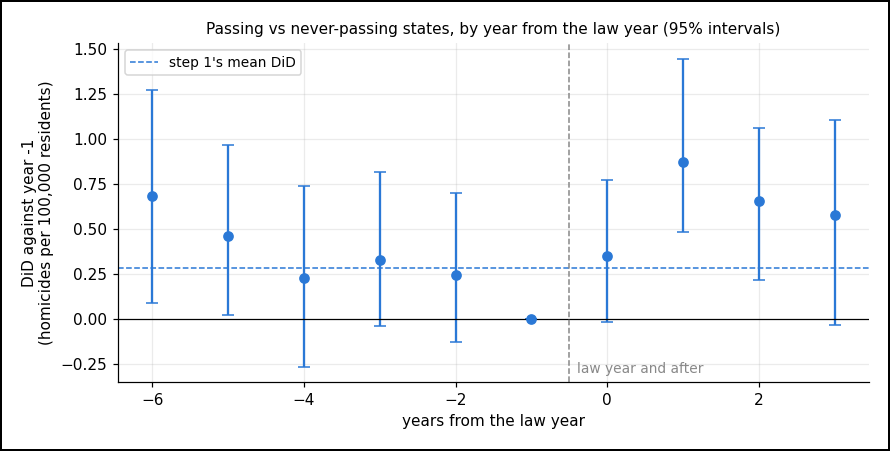

In [16]:
def event_study(d):
    # Mean DiD against year -1, for each year from -6 to 3, each group weighted by its resident-years.
    nv = d[d.law_year.isna()]
    out = {}
    for k in range(-6, 4):
        vals, n_states, weights = [], [], []
        for y in d.law_year.dropna().unique():
            if not 2000 <= y + k <= 2010:
                continue
            grp = d[d.law_year == y]
            at = lambda df, yr: rate(df[df.year == yr])
            vals.append((at(grp, y + k) - at(grp, y - 1)) - (at(nv, y + k) - at(nv, y - 1)))
            n_states.append(grp.state.nunique())
            weights.append(grp.residents.sum())
        out[k] = (np.average(vals, weights=weights), sum(n_states))
    return out

es = event_study(castle)
es_draws = pd.DataFrame([{k: v[0] for k, v in event_study(d).items()} for d in draws])
lo, hi = es_draws.quantile(0.025), es_draws.quantile(0.975)
show(pd.DataFrame([(k, n, f"{v:.3f}", "— (0 by definition)" if k == -1 else f"{lo[k]:.3f} to {hi[k]:.3f}",
                    "—" if k == -1 else ("yes" if lo[k] < 0 < hi[k] else "no")) for k, (v, n) in es.items()],
                  columns=["years from the law year", "states", "DiD against year -1", "95% confidence interval", "interval contains 0?"]))
print("notes:")
print("1. Each interval is counted as in step 1, from the same 1,000 redrawn samples.")
print("2. Every row is calculated like the year 0 calculation above, using that row's year instead of year 0.")
print("3. Every row starts from year -1, not from the year before that row. With consecutive years, a small difference each year could look like chance every time, even though those differences add up over several years.")

ks = list(es)
vals = np.array([es[k][0] for k in ks])
fig, ax = plt.subplots(figsize=(8, 4))
err = np.array([[0 if k == -1 else es[k][0] - lo[k], 0 if k == -1 else hi[k] - es[k][0]] for k in ks]).T
ax.errorbar(ks, vals, yerr=err, fmt="o", color=common.BLUE, capsize=4)
ax.axhline(0, color="black", lw=0.8)
ax.axhline(overall, color=common.BLUE, ls="--", lw=1, label="step 1's mean DiD")
ax.legend(loc="upper left", fontsize=9)
ax.axvline(-0.5, color=common.GREY, ls="--", lw=1)
ax.text(-0.4, ax.get_ylim()[0] + 0.05, "law year and after", fontsize=9, color=common.GREY)
ax.set_xlabel("years from the law year")
ax.set_ylabel("DiD against year -1\n(homicides per 100,000 residents)")
ax.set_title("Passing vs never-passing states, by year from the law year (95% intervals)", fontsize=10)
plt.tight_layout()
plt.show()

**Observation:**
- Years before the law: all 5 DiD estimates are above 0, from 0.230 to 0.684. For example, 0.684 means that six years before the law, the passing states' rate was 0.684 higher against the never-passing states than in year −1. The intervals of year −6 (0.092 to 1.271) and year −5 (0.026 to 0.967) don't contain 0, so the check fails.
- Years after the law: here we want an effect, so we want the 95% confidence intervals to exclude 0, the opposite of the years before the law. The DiD estimates run from 0.353 to 0.874, and the intervals of years 1 and 2 exclude 0. Only year 1, 0.874, is above every year before the law.
- The DiD estimates of years 0 to 3 (0.353, 0.874, 0.658, 0.581) are above step 1's mean DiD, 0.285, the dashed line on the chart.

**Conclusion:**
- The check fails: before the law, the passing states' rate was already improving against the never-passing states' rate. So the never-passing states are a doubtful stand-in.
- This data shows no sign that the law reduced homicides: the DiD estimates after the law all point to a rise, but the size of the rise can't be trusted, because the check on the years before the law fails.

### Step 3 of 3: the one-regression shortcut

Step 1 calculated one DiD for each law-year group, then averaged them. Analysts usually get one DiD number a shorter way: a single regression on all the states and years. Does that shortcut give about the same number as step 1's mean DiD?

**The motive:** many analyses use this one regression instead of step 1's groups, so an analyst will meet it. It's called two-way fixed effects, and it's called the shortcut below.

- The shortcut predicts each state's homicide rate in each year from a 1/0 column "law in force" (1 from the law year on).
- The shortcut does the same subtraction as step 1's DiD, with one difference. Step 1 subtracts the change of the never-passing states. The shortcut subtracts the change of all the other states, including states that already passed the law.
- The coefficient of "law in force" is the shortcut's DiD estimate. A state-year with more residents counts more.

The risk: earlier-passing states also stand in for later-passing states. But the change of an earlier-passing state can include the law's effect, not only what would have happened anyway. So the shortcut's estimate can't be fully trusted.

Step 1 uses only the never-passing states as the stand-in, so step 1 doesn't have this risk.

In [17]:
def shortcut(d):
    # Homicide rate on "law in force", one column per state and one per year, each state-year counted by its residents.
    d = d.assign(homicide_rate=d.homicides / d.residents * 100_000, law_in_force=(d.year >= d.law_year).astype(float))
    X = np.column_stack([d.law_in_force, pd.get_dummies(d.state, dtype=float), pd.get_dummies(d.year, drop_first=True, dtype=float)])
    root_w = np.sqrt(d.residents.to_numpy(float))
    return np.linalg.lstsq(X * root_w[:, None], d.homicide_rate.to_numpy() * root_w, rcond=None)[0][0]

est = round(shortcut(castle), 3)
low_s, high_s = np.percentile([shortcut(d) for d in draws], [2.5, 97.5])
print(f"Shortcut's DiD estimate (the coefficient of 'law in force') = {est:.3f}")
print("note: the regression calculates this number from all 550 state-years at once, so the number has no short formula like step 1's.")
print()
print(f"95% confidence interval of the shortcut's DiD estimate (bootstrap, 1,000 draws) = {low_s:.3f} to {high_s:.3f}")
print("note: counted as in step 1, from the same 1,000 redrawn samples.")
print()
print("Difference between the two estimates")
print("    = (shortcut's DiD estimate) - (step 1's mean DiD)")
print(f"    = {est:.3f} - {overall:.3f} = {round(est - overall, 3):.3f}")

Shortcut's DiD estimate (the coefficient of 'law in force') = 0.265
note: the regression calculates this number from all 550 state-years at once, so the number has no short formula like step 1's.

95% confidence interval of the shortcut's DiD estimate (bootstrap, 1,000 draws) = -0.067 to 0.557
note: counted as in step 1, from the same 1,000 redrawn samples.

Difference between the two estimates
    = (shortcut's DiD estimate) - (step 1's mean DiD)
    = 0.265 - 0.285 = -0.020


**Observation:** the shortcut's DiD estimate, 0.265, is 0.020 below step 1's mean DiD, 0.285. The shortcut's interval, (−0.067) to 0.557, contains 0, as step 1's does.

**Conclusion:**
- Here the shortcut and step 1 nearly agree, so the risk doesn't move the estimate much on this data.
- The shortcut also relies on the never-passing states. In step 2, the never-passing states failed as a stand-in in the years before the law. So the shortcut's estimate has that same doubt.
- When an effect keeps growing and groups start at different times, the shortcut and step 1 can differ a lot (Goodman-Bacon, 2021). Then report step 1's mean DiD, which doesn't have the risk.

## Exercise — DiD with the CPS men

Redo worked examples 1 and 2 with a different comparison group: the 15,992 CPS (Current Population Survey, a monthly US labour survey) men, instead of the PSID men. For DiD with weighting, fit the scores with the same 8 columns on the 185 treated men and the CPS men.

Write your answers first, then read the answers below.

### Questions

1. What is the DiD ATT estimate, its 95% confidence interval, and its distance above the benchmark (the benchmark is $1,794.3)?
2. Repeat worked example 1 step 2 on the CPS men. Before the program, from 1974 to 1975, did the treated men's and the CPS men's mean earnings change alike? Does the 95% confidence interval of the difference between the two changes contain 0? Then split each group into men with $0 in 1974 and men above $0 in 1974: what does the split show?
3. The lottery check: what is the parallel-trends gap? Is the difference between the lottery men's and the CPS men's share at $0 in 1975 too big to be chance? How does the distance above the benchmark split into two parts?
4. What is the DiD with weighting ATT estimate, its 95% confidence interval and its distance above the benchmark? What is the parallel-trends gap for the weighted CPS men?

### Answers

**Answer 1.**
- CPS men's mean change = (mean 1978 earnings) − (mean 1975 earnings) = 14,846.7 − 13,650.8 = 1,195.9.
- DiD ATT estimate = (treated men's mean change) − (CPS men's mean change) = 4,817.0 − 1,195.9 = 3,621.1.
- Spread of the change, CPS men = square root of ((sum of (man's change − 1,195.9, the CPS men's mean change)²) ÷ (15,992 − 1)) =<br>
  = square root of (951,012,576,085.8 ÷ 15,991) = 7,711.8.
- Standard error = square root of ((spread of the change, treated men)² ÷ 185 + (spread of the change, CPS men)² ÷ 15,992) =<br>
  = square root of (8,275.4² ÷ 185 + 7,711.8² ÷ 15,992) = 611.5.
- 95% confidence interval = (DiD ATT estimate) ± (1.96 × standard error) =<br>
  = 3,621.1 ± (1.96 × 611.5) = 3,621.1 ± 1,198.5 = 2,422.6 to 4,819.6.
- Distance above the benchmark = (DiD ATT estimate) − (benchmark) = 3,621.1 − 1,794.3 = 1,826.8. The interval doesn't contain the benchmark, so the DiD ATT estimate disagrees with the benchmark.

**Answer 2.** Yes, the interval contains 0, so the check passes, meaning the two groups' earnings may have changed alike before the program. Earlier change = a man's change from 1974 to 1975. The split shows the pass is even weaker.
- CPS men's mean earlier change = (mean 1975 earnings) − (mean 1974 earnings) = 13,650.8 − 14,016.8 = (−366.0).
- Difference in earlier change = (treated men's mean earlier change) − (CPS men's mean earlier change) = (−563.5) − (−366.0) = (−197.5).
- Spread of the earlier change, CPS men = square root of ((sum of (man's earlier change − group's mean earlier change)²) ÷ (15,992 − 1)) =<br>
  = square root of (369,769,977,277.7 ÷ 15,991) = 4,808.7.
- Standard error = square root of ((spread of the earlier change, treated men)² ÷ 185 + (spread of the earlier change, CPS men)² ÷ 15,992) =<br>
  = square root of (3,784.0² ÷ 185 + 4,808.7² ÷ 15,992) = 280.8.
- 95% confidence interval = (difference in earlier change) ± (1.96 × standard error) =<br>
  = (−197.5) ± (1.96 × 280.8) = (−197.5) ± 550.4 = (−747.9) to 352.9.
- Split by 1974 earnings: among the men at $0, the treated men's mean earlier change, 434.2, is $1,031.6 below the CPS men's, 1,465.8. Among the men above $0, the treated men's, (−2,983.8), is $2,368.9 below the CPS men's, (−614.9). Both are far larger than (−$197.5): the difference in mix hides them, with 70.8% of the treated men at $0 in 1974, against 12.0% of the CPS men.

**Answer 3.**
- Parallel-trends gap = (lottery men's mean change) − (CPS men's mean change) = 3,287.9 − 1,195.9 = 2,092.0.
- Standard error of the parallel-trends gap = square root of ((spread of the change, lottery men)² ÷ 260 + (spread of the change, CPS men)² ÷ 15,992) =<br>
  = square root of (6,059.8² ÷ 260 + 7,711.8² ÷ 15,992) = 380.7.
- 95% confidence interval = (parallel-trends gap) ± (1.96 × standard error) =<br>
  = 2,092.0 ± (1.96 × 380.7) = 2,092.0 ± 746.2 = 1,345.8 to 2,838.2. The interval doesn't contain 0, so the CPS men are a poor stand-in for the treated men without the program.
- Difference in the share at $0 in 1975 = (lottery men's share) − (CPS men's share) = 68.5% − 10.9% = 57.6 percentage points.
- Standard error of the difference in the share = square root of ((share × (1 − share) ÷ men, lottery men) + (share × (1 − share) ÷ men, CPS men)) =<br>
  = square root of ((0.685 × 0.315 ÷ 260) + (0.109 × 0.891 ÷ 15,992)) = 2.9 percentage points.
- 95% confidence interval = (difference in the share) ± (1.96 × standard error) =<br>
  = 57.6 ± (1.96 × 2.9) = 57.6 ± 5.7 = 51.9 to 63.3 percentage points. The interval doesn't contain 0, so the difference is too big to be chance.
- Distance above the benchmark = (parallel-trends gap) − (baseline imbalance: treated men's mean 1975 earnings − lottery men's mean 1975 earnings) =<br>
  = 2,092.0 − (1,532.1 − 1,266.9) = 2,092.0 − 265.2 = 1,826.8.

**Answer 4.**
- CPS men's weighted mean change = (sum of (weight × change)) ÷ (sum of the weights) = 663,111.4 ÷ 184.185 = 3,600.2.
- DiD with weighting ATT estimate = (treated men's mean change) − (CPS men's weighted mean change) = 4,817.0 − 3,600.2 = 1,216.8.
- 95% confidence interval of the DiD with weighting ATT estimate (bootstrap, 1,000 draws) = (−102.9) to 2,570.0.
- Distance above the benchmark = (DiD with weighting ATT estimate) − (benchmark) = 1,216.8 − 1,794.3 = (−577.5): $577.5 below the benchmark.
- Parallel-trends gap, weighted CPS men = (lottery men's mean change) − (CPS men's weighted mean change) = 3,287.9 − 3,600.2 = (−312.3).
- 95% confidence interval of the parallel-trends gap, weighted CPS men (bootstrap, 1,000 draws, also redrawing the 260 lottery men) = (−1,217.0) to 599.8. The interval contains 0, so the gap could be chance.

**What the CPS answers show:**
- The check on the years before the program passed, yet the DiD ATT estimate is $1,826.8 above the benchmark. So passing that check is no proof that the DiD ATT estimate is right.
- The weights help a lot: the distance from the benchmark shrinks from $1,826.8 above to $577.5 below. On this data, closer to the benchmark means more accurate.
- But DiD with weighting can't rule out no effect: the DiD with weighting interval, (−$102.9) to $2,570.0, contains 0.

## Interview angle

> "We launched feature X in the markets where spend had dipped. Spend there rose 8% the next month, against 3% in the other markets. Is X worth 5 points?"

A strong answer: not on its own. The 5 points is a DiD: (launch markets' rise) − (other markets' rise) = 8% − 3%. The other markets' 3% stands in for the launch markets' rise without X.

That stand-in is doubtful: the launch markets were picked after a dip, and spend after a dip tends to rise anyway. So part of the 5 points may not come from X. Three things to do:
- Check earlier months: did the two sets of markets move alike? Failing is a strong warning. Passing proves little.
- Find a better stand-in: markets that also dipped but didn't get X, or the other markets weighted to look like the launch markets.
- If X launched in different months: compare each launch month's markets with markets that never got X, month by month.

## Key takeaways

- DiD ATT = (treated group's mean change) − (comparison group's mean change). The comparison group's change stands in for the treated group's change without the treatment.
- Parallel trends is the assumption that this stand-in is right. On the NSW data, the stand-in was off: the lottery men's mean earnings rose $797.3 more than the PSID men's. So the DiD ATT estimate, $2,326.4, landed $532.1 above the benchmark, $1,794.3.
- A group picked at a low point tends to rise anyway, which can break parallel trends. Most lottery men earned $0 in 1975, few PSID men did, and the men at $0 rose most.
- A passing check on the years before the program is weak evidence: it passed here, and the PSID men were still most likely a poor stand-in. A failing check is a strong warning.
- DiD with weighting removes an earnings gap the weights missed, if that gap was there in both years. On the NSW data, the DiD with weighting ATT estimate was $1,962.6, closer to the benchmark than DiD's, with a wider interval.
- When a change starts in different years: one DiD per start-year group against groups that never changed, then an event study as the check. On the castle-doctrine law, the check failed, so the data can't show that the law changed the homicide rate.
- The one-regression shortcut also uses groups that already changed as a stand-in. Check the shortcut against the per-group DiD.

## Appendix: why the distance above the benchmark splits in two

Write the mean earnings:
- treated men: T75 in 1975, T78 in 1978
- lottery men: L75 in 1975, L78 in 1978
- PSID men: P75 in 1975, P78 in 1978

Then:
1. Benchmark = T78 − L78.
2. DiD ATT = (T78 − T75) − (P78 − P75).
3. Distance above the benchmark = (DiD ATT) − (benchmark) = ((T78 − T75) − (P78 − P75)) − (T78 − L78).
4. Open the brackets: T78 − T75 − P78 + P75 − T78 + L78.
5. T78 and −T78 cancel: L78 − T75 − P78 + P75.
6. To form the lottery men's change, add L75 and take L75 away again: L78 − L75 − P78 + P75 − T75 + L75.
7. Group the terms: ((L78 − L75) − (P78 − P75)) − (T75 − L75).

So distance above the benchmark = (parallel-trends gap) − (baseline imbalance):
- The first bracket is the parallel-trends gap: (lottery men's mean change) − (PSID men's mean change).
- The second bracket is the baseline imbalance: (treated men's mean 1975 earnings) − (lottery men's mean 1975 earnings).

The steps hold for any comparison group's mean change, weighted or not. 

Baseline imbalance = (treated men's mean 1975 earnings) − (lottery men's mean 1975 earnings) = 1,532.1 − 1,266.9 = 265.2.<br>
Distance above the benchmark, PSID men = (parallel-trends gap) − (baseline imbalance) = 797.3 − 265.2 = 532.1.